# Day 42: Customer Segmentation & Service Recommendation System

**Dataset:** the 5,000 clustered customers from Day 41 and the Veda Technology business data from
Days 35 to 38

This notebook is the third of four days in the Customer Segmentation & Service Recommendation
System project. It gives the four clusters from Day 41 meaningful names and profiles, draws the
customers in 2D with PCA, and builds a rule-based service recommendation logic. Day 43 finishes
the project with a customer segment dashboard, business recommendations, and a final report.

## 1. Import Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

# Folders
DATA_DIR = Path("../datasets/veda_customers")
BUSINESS_DIR = Path("../datasets/veda_business/cleaned")
SEGMENT_DIR = DATA_DIR / "segments"
SEGMENT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the Clustered Customers

The clustered customers (with the cluster and silhouette of each customer) and the feature table
(with the standardized clustering features) saved on Day 41 are loaded and joined by customer ID.

In [2]:
customers = pd.read_csv(DATA_DIR / "clustered" / "customers_clustered.csv", parse_dates=["signup_date"])
features = pd.read_csv(DATA_DIR / "features" / "customer_features.csv")

assert (customers["customer_id"] == features["customer_id"]).all(), "the two tables are not in the same order"
data = customers.merge(features, on="customer_id")

Z_COLUMNS = [col for col in features.columns if col.startswith("z_")]
print("Customers:", len(data), "| clusters:", sorted(data["cluster"].unique()), "| standardized features:", len(Z_COLUMNS))
data[["customer_id", "customer_type", "primary_interest", "cluster", "silhouette"] + Z_COLUMNS].head()

Customers: 5000 | clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)] | standardized features: 6


,customer_id,customer_type,primary_interest,cluster,silhouette,z_engagement_score,z_log_days_inactive,z_log_inquiries,z_log_tickets,z_log_spend,z_tenure_days
0,C00001,Student,Training Programs,0,0.3051,1.524517,0.069694,0.777436,-0.644299,0.774006,1.97082
1,C00002,Enterprise,Training Programs,3,0.3120,-0.180338,-0.515679,2.547838,1.473408,0.913913,1.97082
2,C00003,Enterprise,IT Services,3,0.2728,0.478931,0.349817,3.492320,0.691826,1.140613,1.97082
3,C00004,Enterprise,IT Services,0,0.1160,-0.349196,-0.235555,-0.719532,-0.644299,1.112730,1.97082
4,C00005,Student,Internships,0,0.1862,1.550329,-0.515679,-0.719532,2.027950,0.720906,1.97082


## 3. Customer Segment Profiles

**Naming the segments**

The clusters from Day 41 are only numbers. Each one is given a name by a rule that reads its
center (the average of its standardized features), so the names stay correct even if the clusters
are numbered differently. The rule follows the example segments of the project hints:

1. The cluster with the most service inquiries is the **Service-Focused Clients**.
2. Of the rest, the cluster with the shortest tenure is the **New Customers**.
3. Of the rest, the cluster with the highest engagement is the **Engaged Learners**.
4. The cluster that remains is the **Occasional Visitors**, which should have the lowest engagement and the longest inactivity (checked below).

In [3]:
SEGMENT_ORDER = ["Engaged Learners", "Occasional Visitors", "New Customers", "Service-Focused Clients"]
COLORS = {"Engaged Learners": "tab:blue", "Occasional Visitors": "tab:orange", "New Customers": "tab:green", "Service-Focused Clients": "tab:red"}

centers = data.groupby("cluster")[Z_COLUMNS].mean()

names = {}
names[centers["z_log_inquiries"].idxmax()] = "Service-Focused Clients"
names[centers.drop(index=list(names))["z_tenure_days"].idxmin()] = "New Customers"
names[centers.drop(index=list(names))["z_engagement_score"].idxmax()] = "Engaged Learners"
names[[c for c in centers.index if c not in names][0]] = "Occasional Visitors"

data["segment"] = data["cluster"].map(names)

leftover = centers.loc[[c for c, n in names.items() if n == "Occasional Visitors"][0]]
print("The Occasional Visitors have the lowest engagement:", leftover["z_engagement_score"] == centers["z_engagement_score"].min(),
      "| and the longest inactivity:", leftover["z_log_days_inactive"] == centers["z_log_days_inactive"].max())

segment_centers = centers.rename(index=names).loc[SEGMENT_ORDER]
segment_centers.insert(0, "cluster", [c for n in SEGMENT_ORDER for c, v in names.items() if v == n])
segment_centers.round(2)

The Occasional Visitors have the lowest engagement: True | and the longest inactivity: True


,cluster,z_engagement_score,z_log_days_inactive,z_log_inquiries,z_log_tickets,z_log_spend,z_tenure_days
cluster,,,,,,,
Engaged Learners,0,1.19,-0.69,-0.22,-0.20,0.67,0.32
Occasional Visitors,1,-1.07,1.24,-0.49,-0.41,-0.82,0.49
New Customers,2,-0.36,-0.46,-0.36,-0.26,-0.49,-1.04
Service-Focused Clients,3,0.12,-0.10,1.67,1.37,0.81,0.16


**Segment overview: size and value**

In [4]:
BUSINESS_TYPES = ["Small Business", "Startup", "Enterprise", "Educational Institution"]
data["is_buyer"] = data["purchases"] > 0
grouped = data.groupby("segment")

overview = pd.DataFrame({
    "customers": grouped.size(),
    "share_of_customers_pct": grouped.size() / len(data) * 100,
    "buyers_pct": grouped["is_buyer"].mean() * 100,
    "median_spend_inr": grouped["total_spend_inr"].median(),
    "avg_spend_inr": grouped["total_spend_inr"].mean(),
    "share_of_total_spend_pct": grouped["total_spend_inr"].sum() / data["total_spend_inr"].sum() * 100,
    "avg_satisfaction": grouped["satisfaction_rating"].mean(),
    "survey_response_pct": grouped["satisfaction_rating"].apply(lambda s: s.notna().mean() * 100),
}).loc[SEGMENT_ORDER]

overview.round(1)

,customers,share_of_customers_pct,buyers_pct,median_spend_inr,avg_spend_inr,share_of_total_spend_pct,avg_satisfaction,survey_response_pct
segment,,,,,,,,
Engaged Learners,1517,30.3,94.9,18100.0,31046.5,22.8,4.3,68.8
Occasional Visitors,1369,27.4,22.6,0.0,1779.1,1.2,3.6,39.0
New Customers,1243,24.9,40.6,0.0,5414.1,3.3,3.9,48.0
Service-Focused Clients,871,17.4,87.0,97900.0,172222.7,72.7,3.6,64.3


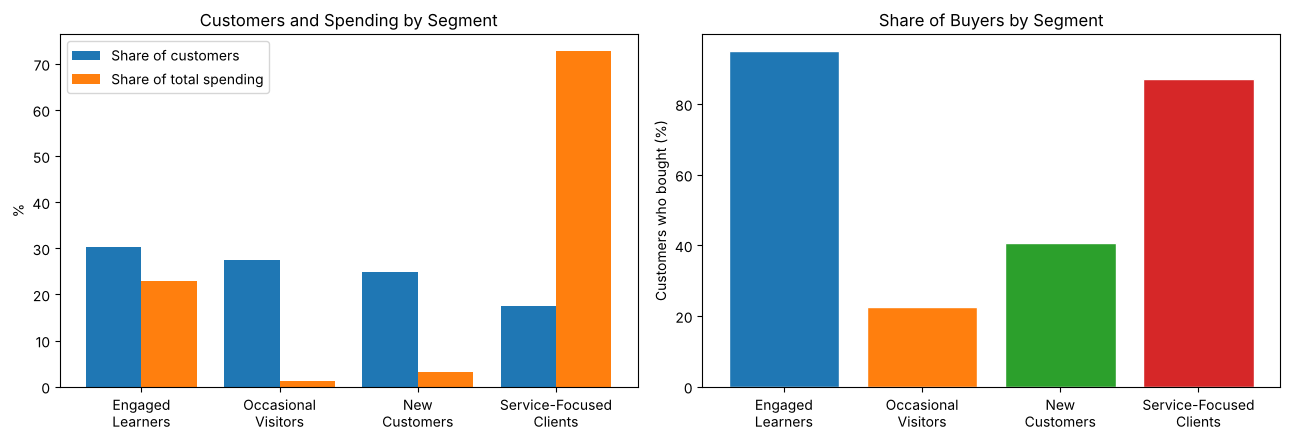

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

positions = np.arange(len(SEGMENT_ORDER))
axes[0].bar(positions - 0.2, overview["share_of_customers_pct"], width=0.4, label="Share of customers")
axes[0].bar(positions + 0.2, overview["share_of_total_spend_pct"], width=0.4, label="Share of total spending")
axes[0].set_xticks(positions)
axes[0].set_xticklabels([name.replace(" ", "\n", 1) for name in SEGMENT_ORDER])
axes[0].set_ylabel("%")
axes[0].set_title("Customers and Spending by Segment")
axes[0].legend()

axes[1].bar(SEGMENT_ORDER, overview["buyers_pct"], color=[COLORS[s] for s in SEGMENT_ORDER], edgecolor="white")
axes[1].set_xticks(range(len(SEGMENT_ORDER)))
axes[1].set_xticklabels([name.replace(" ", "\n", 1) for name in SEGMENT_ORDER])
axes[1].set_ylabel("Customers who bought (%)")
axes[1].set_title("Share of Buyers by Segment")

plt.tight_layout()
plt.show()

**Segment behavior**

In [6]:
behavior = grouped.agg(
    avg_visits=("website_visits", "mean"), avg_session_min=("avg_session_minutes", "mean"), avg_pages=("pages_per_visit", "mean"),
    avg_email_open_pct=("email_open_rate_pct", "mean"), avg_days_inactive=("days_since_last_activity", "mean"),
    avg_inquiries=("service_inquiries", "mean"), avg_tickets=("support_tickets", "mean"), avg_tenure_days=("tenure_days", "mean"),
).loc[SEGMENT_ORDER]

behavior.round(1).T

segment,Engaged Learners,Occasional Visitors,New Customers,Service-Focused Clients
avg_visits,19.4,3.1,6.3,7.9
avg_session_min,9.3,2.9,4.5,7.0
avg_pages,6.4,2.5,3.5,5.1
avg_email_open_pct,54.6,15.1,30.4,28.0
avg_days_inactive,6.1,86.3,9.2,16.8
avg_inquiries,0.6,0.3,0.4,6.1
avg_tickets,0.4,0.2,0.3,2.4
avg_tenure_days,182.8,200.9,32.4,164.9


**Who the segments are: customer type, interest, and acquisition channel**

These three columns were not used for the clustering. Each bar shows the make-up of one segment.

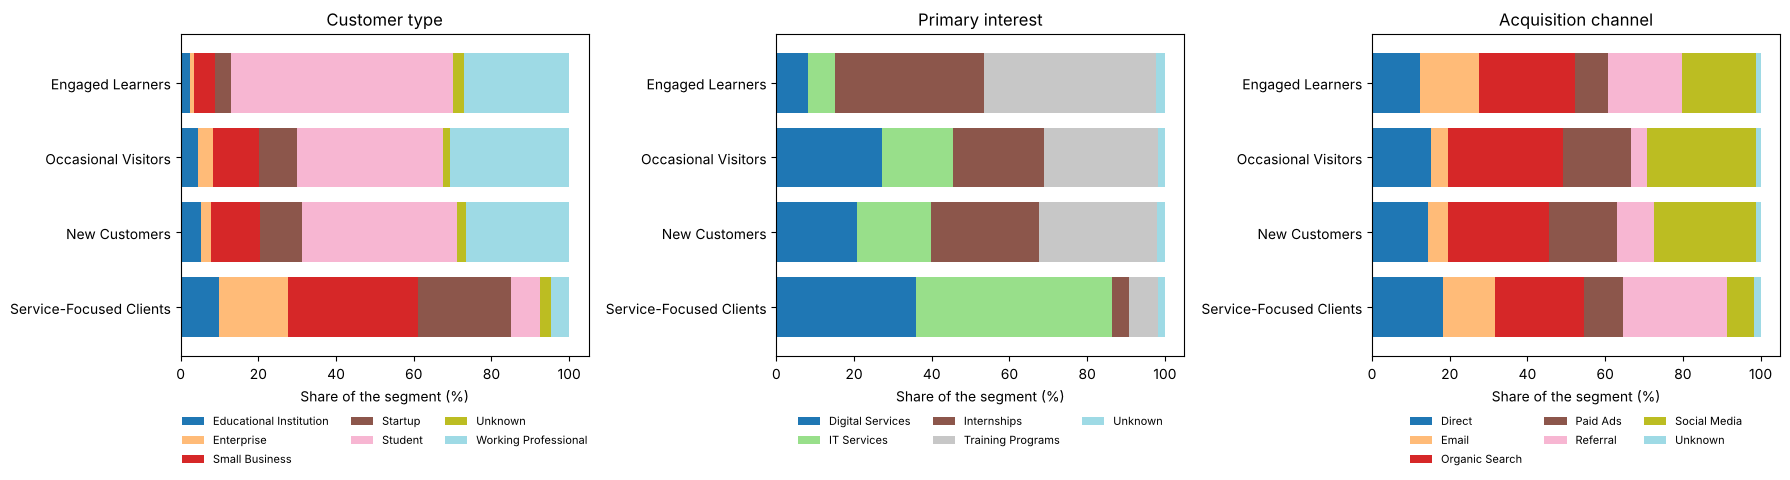

In [7]:
mix_columns = [("customer_type", "Customer type"), ("primary_interest", "Primary interest"), ("acquisition_channel", "Acquisition channel")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, title) in zip(axes, mix_columns):
    mix = pd.crosstab(data["segment"], data[col], normalize="index").mul(100).loc[SEGMENT_ORDER]
    mix.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", width=0.8)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Share of the segment (%)")
    ax.set_ylabel("")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

In [8]:
def top_category(column):
    shares = pd.crosstab(data["segment"], data[column], normalize="index").mul(100)
    shares = shares.drop(columns="Unknown", errors="ignore")
    return shares.idxmax(axis=1), shares.max(axis=1)


top_interest, top_interest_pct = top_category("primary_interest")
top_channel, top_channel_pct = top_category("acquisition_channel")

who = pd.DataFrame({
    "business_customers_pct": grouped["customer_type"].apply(lambda s: s.isin(BUSINESS_TYPES).mean() * 100),
    "students_and_professionals_pct": grouped["customer_type"].apply(lambda s: s.isin(["Student", "Working Professional"]).mean() * 100),
    "top_interest": top_interest, "top_interest_pct": top_interest_pct,
    "top_channel": top_channel, "top_channel_pct": top_channel_pct,
    "referral_or_email_pct": grouped["acquisition_channel"].apply(lambda s: s.isin(["Referral", "Email"]).mean() * 100),
}).loc[SEGMENT_ORDER]

who.round(1)

,business_customers_pct,students_and_professionals_pct,top_interest,top_interest_pct,top_channel,top_channel_pct,referral_or_email_pct
segment,,,,,,,
Engaged Learners,13.0,84.3,Training Programs,44.3,Organic Search,24.6,34.3
Occasional Visitors,29.9,68.4,Training Programs,29.5,Organic Search,29.7,8.4
New Customers,31.2,66.4,Training Programs,30.3,Social Media,26.1,14.7
Service-Focused Clients,85.1,12.1,IT Services,50.4,Referral,26.8,40.3


**Observation:** The rule gave each cluster a name, and the name fits the numbers. The **Engaged Learners** (1,517 customers, 30%) visit 19.4 times on average, open 54.6% of emails, were last active 6 days ago, and 95% have bought; they are mostly students and working professionals (84%) and have the highest satisfaction (4.3). The **Occasional Visitors** (1,369, 27%) visit 3.1 times, open 15% of emails, and were last active 86 days ago; only 23% have bought, the median spending is INR 0, and they hold 1.2% of all spending. The **New Customers** (1,243, 25%) signed up 32 days ago on average (against 165 to 201 for the others), engage moderately, and 41% have bought. The **Service-Focused Clients** (871, 17%) send 6.1 inquiries and 2.4 support tickets each, 85% are business customers, and they hold 72.7% of all spending (an average of INR 172,223, against INR 31,046 for the Engaged Learners), but their satisfaction is low (3.6). The segments therefore differ in both size and value: the smallest segment is worth far more than the other three together. The customer type, interest, and channel were not used for the clustering, and they still differ clearly: Service-Focused Clients prefer IT Services (50%) and come most often through Referral, while the Engaged Learners lean to Training Programs (44%) and the learner customer types.

**The segment profiles**

The numbers above are brought together in one table with a plain-language profile of each
segment, which is the reference for the recommendation logic and the dashboard on Day 43.

In [9]:
segment_profiles = pd.concat([segment_centers[["cluster"]], overview, behavior, who], axis=1)
segment_profiles.index.name = "segment"
segment_profiles.round(2).to_csv(SEGMENT_DIR / "segment_profiles.csv")

print("Saved:", SEGMENT_DIR / "segment_profiles.csv", "| segments:", len(segment_profiles), "| columns:", segment_profiles.shape[1])

Saved: ../datasets/veda_customers/segments/segment_profiles.csv | segments: 4 | columns: 24


| Segment | Who they are | What they do | Value to Veda Technology | What they need |
|---|---|---|---|---|
| **Engaged Learners** | Mostly students and working professionals (84%), interested in learning (Training Programs 44%) | 19.4 visits, 54.6% email opens, last active 6 days ago | 30% of customers, 95% have bought, 22.8% of spending, highest satisfaction (4.3) | The next learning step, and a referral invitation when satisfied |
| **Occasional Visitors** | A mix of customer types, mostly learners, with few referral or email customers (8%) | 3.1 visits, 15% email opens, last active 86 days ago | 27% of customers, 23% have bought, 1.2% of spending | Re-engagement with something relevant to their interest |
| **New Customers** | Signed up about a month ago (32 days on average), a mix of customer types | 6.3 visits, 30% email opens, last active 9 days ago | 25% of customers, 41% have bought, 3.3% of spending | A welcome series that leads to the first purchase |
| **Service-Focused Clients** | Business customers (85%), IT Services interest (50%), often from Referral (27%) | 6.1 inquiries and 2.4 support tickets each, 7.9 visits | 17% of customers, 87% have bought, 72.7% of spending, low satisfaction (3.6) | A dedicated account manager, fast replies, and service recovery when needed |

## 4. 2D Cluster Visualization with PCA

The clustering used six features, which cannot be drawn on a flat chart. **PCA** (principal
component analysis) finds the two directions along which the standardized features vary the
most, and every customer is placed on those two axes. The picture is a simplification: the
clusters were found in six dimensions, so two clusters that overlap in the picture may still be
separate in the full data.

**How much of the information the two axes keep**

In [10]:
pca = PCA(n_components=len(Z_COLUMNS)).fit(data[Z_COLUMNS])

variance = pd.DataFrame({
    "explained_variance_pct": pca.explained_variance_ratio_ * 100,
    "cumulative_pct": pca.explained_variance_ratio_.cumsum() * 100,
}, index=[f"PC{i + 1}" for i in range(len(Z_COLUMNS))])
display(variance.round(1).T)

loadings = pd.DataFrame(pca.components_[:2].T, index=Z_COLUMNS, columns=["PC1", "PC2"])
print("What the first two axes are made of (a larger value means a stronger link):")
loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
explained_variance_pct,37.0,22.6,17.2,9.9,8.4,5.0
cumulative_pct,37.0,59.6,76.8,86.7,95.0,100.0


What the first two axes are made of (a larger value means a stronger link):


,PC1,PC2
z_engagement_score,0.52,-0.28
z_log_days_inactive,-0.47,0.46
z_log_inquiries,0.35,0.49
z_log_tickets,0.32,0.50
z_log_spend,0.53,0.06
z_tenure_days,0.01,0.46


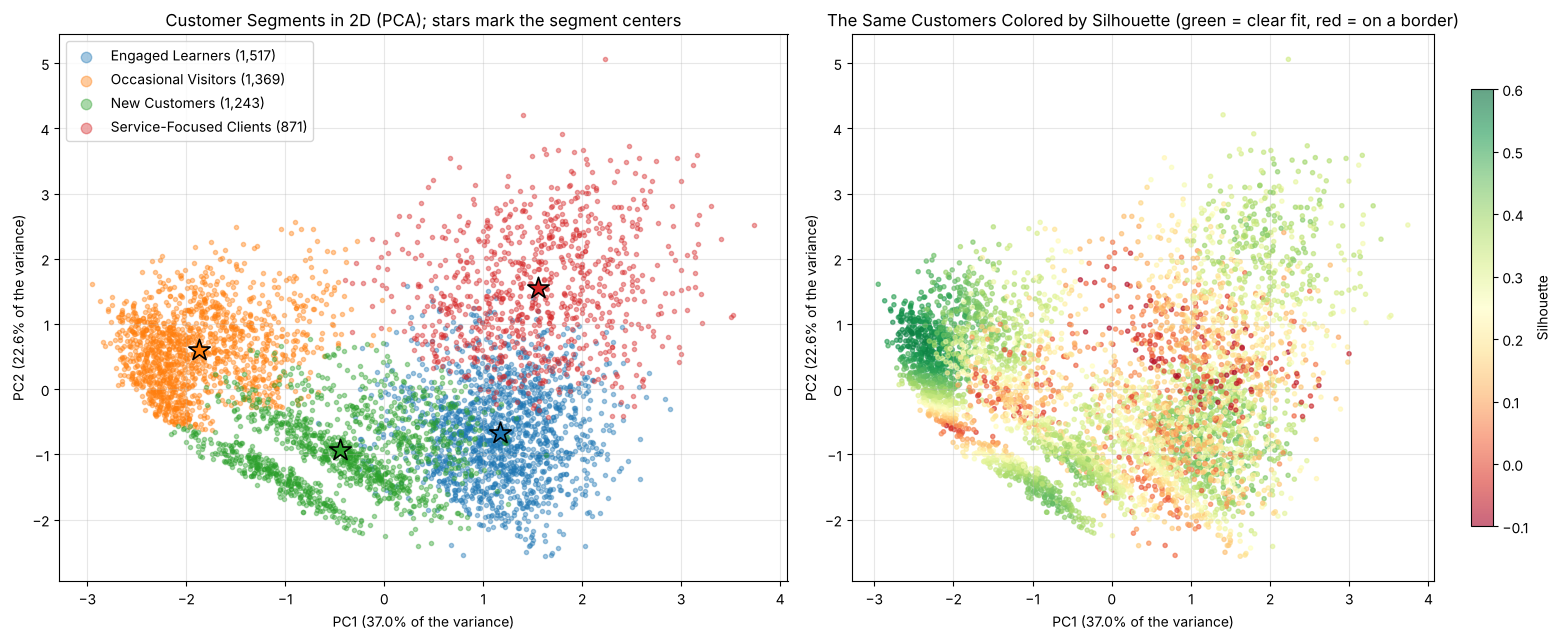

In [11]:
coords = pca.transform(data[Z_COLUMNS])[:, :2]
data["pc1"], data["pc2"] = coords[:, 0], coords[:, 1]
centers_2d = pca.transform(segment_centers[Z_COLUMNS])[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

for segment in SEGMENT_ORDER:
    rows = data["segment"] == segment
    axes[0].scatter(data.loc[rows, "pc1"], data.loc[rows, "pc2"], s=9, alpha=0.4, color=COLORS[segment], label=f"{segment} ({rows.sum():,})")
for (x, y), segment in zip(centers_2d, SEGMENT_ORDER):
    axes[0].scatter(x, y, s=260, marker="*", color=COLORS[segment], edgecolor="black", linewidth=1.2, zorder=3)
axes[0].set_title("Customer Segments in 2D (PCA); stars mark the segment centers")
axes[0].legend(markerscale=2.5, loc="upper left")

points = axes[1].scatter(data["pc1"], data["pc2"], c=data["silhouette"], cmap="RdYlGn", vmin=-0.1, vmax=0.6, s=9, alpha=0.6)
axes[1].set_title("The Same Customers Colored by Silhouette (green = clear fit, red = on a border)")
fig.colorbar(points, ax=axes[1], shrink=0.8, label="Silhouette")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% of the variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% of the variance)")
    ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("customer_segments_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**How faithful is the 2D picture?**

If every customer is given to the nearest segment center in the 2D picture, how many customers
end up in the segment they have in the full six-dimensional clustering?

In [12]:
distances = ((coords[:, None, :] - centers_2d[None, :, :]) ** 2).sum(axis=2)
nearest_in_2d = np.array(SEGMENT_ORDER)[distances.argmin(axis=1)]
agreement = (nearest_in_2d == data["segment"].to_numpy())

print(f"The 2D picture keeps {variance['cumulative_pct'].iloc[1]:.1f}% of the information (variance) of the six features.")
print(f"Nearest segment center in 2D matches the real segment for {agreement.mean() * 100:.1f}% of the customers.")
pd.Series(agreement).groupby(data["segment"].to_numpy()).mean().mul(100).round(1).loc[SEGMENT_ORDER].to_frame("matching_in_2d_pct")

The 2D picture keeps 59.6% of the information (variance) of the six features.
Nearest segment center in 2D matches the real segment for 89.0% of the customers.


,matching_in_2d_pct
Engaged Learners,87.7
Occasional Visitors,98.4
New Customers,80.6
Service-Focused Clients,88.3


**Observation:** The first two axes keep 59.6% of the variance, so about 40% of the information is not in the picture. The first axis (37.0%) separates customers who are engaged, active, and spending (right) from inactive and low-spending ones (left), and the second axis (22.6%) is mostly service use (inquiries and tickets), recency, and tenure. In the picture the Occasional Visitors form a compact group on the left, the New Customers a diagonal band along the bottom (the band comes from the tenure feature, which is short for all of them), the Engaged Learners a dense group on the lower right, and the Service-Focused Clients a wide group on the upper right that is spread out and touches the Engaged Learners. The silhouette colors agree with this: the Occasional Visitors are the clearest (dark green), while the borders between the Engaged Learners, the New Customers, and the Service-Focused Clients are yellow and red. The nearest 2D center gives the same segment for 89.0% of the customers, from 98.4% for the Occasional Visitors to 80.6% for the New Customers. The overlap in the picture is partly caused by the 40% of the variance that is not shown, so the segments are better separated than the picture suggests, but the clusters are certainly not sharply separated blobs.

## 5. Service Recommendation Logic

The project hint says that the recommendations can be **rule-based**, so the logic is a short
list of explicit rules, which is easy to explain, check, and change, and needs no outcome data
that does not exist (the data has no record of which offer a customer accepted).

**The Veda Technology offers**

The offers come from the business data of Days 35 to 38: the eight internship domains, six
training programs, five IT services, and five digital services. Customers record their interest
only at the level of the four offer families (Internships, Training Programs, IT Services, and
Digital Services), so the rules choose a family first and then the offer inside it.

Two ways of ranking the offers inside a family are possible: by **demand** (how many applications,
enrollments, or inquiries it receives) or by **outcome** (selection, completion, or conversion rate).
A test shows whether the outcome rates really differ between the offers of a family. If they do
not, ranking by outcome would only follow chance.

In [13]:
FAMILY_SOURCES = {
    "Internship Programs": ("internship_applications_cleaned.csv", "domain", "application_id", "selection_rate_pct", lambda df: df["status"].eq("Selected")),
    "Training Programs": ("training_enrollments_cleaned.csv", "program", "enrollment_id", "completion_rate_pct", lambda df: df["completed"].eq(1)),
    "IT Services": ("it_service_inquiries_cleaned.csv", "service_type", "inquiry_id", "conversion_rate_pct", lambda df: df["status"].eq("Converted")),
    "Digital Services": ("digital_service_inquiries_cleaned.csv", "service_type", "inquiry_id", "conversion_rate_pct", lambda df: df["status"].eq("Converted")),
}

catalog_rows = []
for family, (file_name, item_col, id_col, outcome_name, outcome) in FAMILY_SOURCES.items():
    table = pd.read_csv(BUSINESS_DIR / file_name)
    table = table[table[item_col] != "Unknown"].assign(success=lambda df: outcome(df))
    p_value = chi2_contingency(pd.crosstab(table[item_col], table["success"]))[1]
    by_item = table.groupby(item_col).agg(demand=(id_col, "count"), outcome_rate_pct=("success", "mean"))
    by_item["outcome_rate_pct"] *= 100
    for rank, (item, row) in enumerate(by_item.sort_values("demand", ascending=False).iterrows(), start=1):
        catalog_rows.append({"family": family, "offer": item, "demand": int(row["demand"]), "demand_rank": rank,
                             "outcome_measure": outcome_name, "outcome_rate_pct": round(row["outcome_rate_pct"], 1),
                             "p_value_outcomes_differ": round(p_value, 3)})

catalog = pd.DataFrame(catalog_rows)
catalog.to_csv(SEGMENT_DIR / "service_catalog.csv", index=False)
catalog

,family,offer,demand,demand_rank,outcome_measure,outcome_rate_pct,p_value_outcomes_differ
0,Internship Programs,Data Science,578,1,selection_rate_pct,36.0,0.242
1,Internship Programs,Web Development,513,2,selection_rate_pct,36.6,0.242
2,Internship Programs,AI / Machine Learning,376,3,selection_rate_pct,34.6,0.242
3,Internship Programs,Digital Marketing,323,4,selection_rate_pct,35.9,0.242
4,Internship Programs,Cyber Security,236,5,selection_rate_pct,30.9,0.242
5,Internship Programs,UI/UX Design,231,6,selection_rate_pct,43.7,0.242
6,Internship Programs,Cloud Computing,212,7,selection_rate_pct,34.9,0.242
7,Internship Programs,Business Analytics,131,8,selection_rate_pct,36.6,0.242
8,Training Programs,Full Stack Web Development,412,1,completion_rate_pct,64.1,0.918
9,Training Programs,Data Analytics,360,2,completion_rate_pct,67.8,0.918


**Observation:** The catalog has 24 offers in 4 families. The offers are ranked by demand because the outcome rates inside a family do not differ significantly (chi-square p-values of 0.24 for internships, 0.92 for training, 0.27 for IT services, and 0.59 for digital services, all above 0.05). Some gaps look large, for example the selection rate of UI/UX Design internships (43.7%) against Cyber Security (30.9%), but with eight offers and a few hundred applications each, differences of this size can come from chance. The most demanded offers are therefore Data Science (internships), Full Stack Web Development (training), Software Development (IT services), and Website Design & Development (digital services), and they are the offers the rules recommend. A limit of this design is that customers record their interest only at the level of the family, so everyone with the same interest gets the same lead offer; with data on the offers each customer viewed or bought, the rules could be personalized further.

**The rules**

| Rule | Condition | Result |
|---|---|---|
| **R1** | The customer's primary interest is known | The primary offer family is that interest (Internships, Training Programs, IT Services, or Digital Services) |
| **R1b** | The interest is unknown | The primary offer family is the most common interest in the customer's segment |
| **R2** | Always | The cross-sell family is the neighboring one: Internship Programs and Training Programs go together, and so do IT Services and Digital Services |
| **R3** | Always | The offer of a family is its most demanded item in the business data |
| **R4** | Always | The segment action in the table below |
| **R5** | 3 or more support tickets, or a satisfaction rating of 2 or less | Service recovery first: resolve the open issues, and only then follow the segment action |
| **R6** | Engaged Learners with a satisfaction rating of 4 or 5 | Also invite the customer to the referral program |
| **R7** | Silhouette of 0.25 or more and a known interest: **High**; silhouette below 0.10: **Low**; anything else: **Medium** | The confidence of the recommendation, which is lower for customers near a segment border or with an unknown interest |

| Segment | Action (R4) | Why |
|---|---|---|
| Engaged Learners | Offer the next learning step (a more advanced program or an internship) | They are active, almost all have bought, and they are the most satisfied, so the next step is a deeper offer. Satisfied customers also bring in others (R6) |
| Occasional Visitors | Send a re-engagement email that features the primary offer | They have been inactive for months and rarely buy, so the first job is to bring them back with something relevant to their interest |
| New Customers | Start a welcome series that introduces the primary offer and aims at the first purchase | They are recent and moderately engaged, and less than half have bought, so the goal is the first purchase |
| Service-Focused Clients | Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together | They ask the most questions and hold most of the spending, and the business analysis (Day 38) found that inquiries answered within 4 hours convert much more often |

In [14]:
INTEREST_TO_FAMILY = {"Internships": "Internship Programs", "Training Programs": "Training Programs", "IT Services": "IT Services", "Digital Services": "Digital Services"}
CROSS_SELL_FAMILY = {"Internship Programs": "Training Programs", "Training Programs": "Internship Programs", "IT Services": "Digital Services", "Digital Services": "IT Services"}
SEGMENT_ACTIONS = {
    "Engaged Learners": "Offer the next learning step (a more advanced program or an internship)",
    "Occasional Visitors": "Send a re-engagement email that features the primary offer",
    "New Customers": "Start a welcome series that introduces the primary offer and aims at the first purchase",
    "Service-Focused Clients": "Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together",
}

# R3: the most demanded offer of each family
lead_offer = catalog[catalog["demand_rank"] == 1].set_index("family")["offer"]

# R1b: the most common known interest of each segment
segment_default_interest = data[data["primary_interest"].isin(INTEREST_TO_FAMILY)].groupby("segment")["primary_interest"].agg(lambda s: s.mode().iloc[0])


def recommend(df):
    known_interest = df["primary_interest"].isin(INTEREST_TO_FAMILY)
    interest = df["primary_interest"].where(known_interest, df["segment"].map(segment_default_interest))   # R1 / R1b

    out = pd.DataFrame({"customer_id": df["customer_id"], "segment": df["segment"]})
    out["primary_family"] = interest.map(INTEREST_TO_FAMILY)
    out["primary_offer"] = out["primary_family"].map(lead_offer)                       # R3
    out["cross_sell_family"] = out["primary_family"].map(CROSS_SELL_FAMILY)             # R2
    out["cross_sell_offer"] = out["cross_sell_family"].map(lead_offer)                  # R3

    recovery = (df["support_tickets"] >= 3) | (df["satisfaction_rating"] <= 2)          # R5
    referral = (df["segment"] == "Engaged Learners") & (df["satisfaction_rating"] >= 4)  # R6
    action = df["segment"].map(SEGMENT_ACTIONS)                                           # R4
    action = np.where(recovery, "Resolve the open service issues first, then: " + action.str[0].str.lower() + action.str[1:], action)
    out["action"] = np.where(referral, pd.Series(action, index=df.index) + "; also invite to the referral program", action)

    out["confidence"] = np.select(                                                         # R7
        [df["silhouette"] < 0.10, (df["silhouette"] >= 0.25) & known_interest], ["Low", "High"], default="Medium")

    out["rules_applied"] = (np.where(known_interest, "R1, ", "R1b, ") + "R2, R3, R4"
                            + np.where(recovery, ", R5", "") + np.where(referral, ", R6", ""))
    out["reason"] = (df["segment"] + "; "
                     + np.where(known_interest, "interested in " + interest, "interest unknown, using the segment's most common one (" + interest + ")")
                     + np.where(recovery, "; " + df["support_tickets"].astype(str) + " support tickets", ""))
    return out


recommendations = recommend(data)
recommendations.head()

,customer_id,segment,primary_family,primary_offer,cross_sell_family,cross_sell_offer,action,confidence,rules_applied,reason
0,C00001,Engaged Learners,Training Programs,Full Stack Web Development,Internship Programs,Data Science,Offer the next learning step (a more advanced program or an internship),High,"R1, R2, R3, R4",Engaged Learners; interested in Training Programs
1,C00002,Service-Focused Clients,Training Programs,Full Stack Web Development,Internship Programs,Data Science,"Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together",High,"R1, R2, R3, R4",Service-Focused Clients; interested in Training Programs
2,C00003,Service-Focused Clients,IT Services,Software Development,Digital Services,Website Design & Development,"Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together",High,"R1, R2, R3, R4",Service-Focused Clients; interested in IT Services
3,C00004,Engaged Learners,IT Services,Software Development,Digital Services,Website Design & Development,Offer the next learning step (a more advanced program or an internship),Medium,"R1, R2, R3, R4",Engaged Learners; interested in IT Services
4,C00005,Engaged Learners,Internship Programs,Data Science,Training Programs,Full Stack Web Development,"Resolve the open service issues first, then: offer the next learning step (a more advanced program or an internship)...",Medium,"R1, R2, R3, R4, R5, R6",Engaged Learners; interested in Internships; 3 support tickets


**Checking the recommendations**

There is no record of which offers customers accepted, so the recommendations cannot be scored
against outcomes. What can be checked is that the rules behave as designed: every customer gets a
complete recommendation, the primary offer follows the stated interest, the actions fit the
segments, and the confidence levels are reasonable.

In [15]:
required = ["primary_family", "primary_offer", "cross_sell_family", "cross_sell_offer", "action", "confidence", "rules_applied", "reason"]
known = data["primary_interest"].isin(INTEREST_TO_FAMILY)
matches_interest = recommendations.loc[known, "primary_family"] == data.loc[known, "primary_interest"].map(INTEREST_TO_FAMILY)

print("Customers with a complete recommendation:", int(recommendations[required].notna().all(axis=1).sum()), "of", len(recommendations))
print(f"Primary family matches the stated interest (known interests): {matches_interest.mean() * 100:.1f}% of {int(known.sum()):,} customers")
print("Customers whose interest was unknown and filled by the segment default (R1b):", int((~known).sum()))
print()
print("Primary offer family by segment (% of the segment):")
(pd.crosstab(recommendations["segment"], recommendations["primary_family"], normalize="index") * 100).round(0).astype(int).loc[SEGMENT_ORDER]

Customers with a complete recommendation: 5000 of 5000
Primary family matches the stated interest (known interests): 100.0% of 4,903 customers
Customers whose interest was unknown and filled by the segment default (R1b): 97

Primary offer family by segment (% of the segment):


primary_family,Digital Services,IT Services,Internship Programs,Training Programs
segment,,,,
Engaged Learners,8,7,38,46
Occasional Visitors,27,18,23,31
New Customers,21,19,28,32
Service-Focused Clients,36,52,4,8


In [16]:
rule_counts = pd.DataFrame({
    "R5_service_recovery": recommendations["rules_applied"].str.contains("R5").groupby(recommendations["segment"]).sum(),
    "R6_referral_invitation": recommendations["rules_applied"].str.contains("R6").groupby(recommendations["segment"]).sum(),
}).loc[SEGMENT_ORDER]
rule_counts["customers"] = recommendations.groupby("segment").size()
rule_counts["R5_pct"] = (rule_counts["R5_service_recovery"] / rule_counts["customers"] * 100).round(1)

print("Confidence level by segment (% of the segment):")
display((pd.crosstab(recommendations["segment"], recommendations["confidence"], normalize="index") * 100).round(0).astype(int).loc[SEGMENT_ORDER][["High", "Medium", "Low"]])
print("How often the exceptions fire:")
rule_counts

Confidence level by segment (% of the segment):


confidence,High,Medium,Low
segment,,,
Engaged Learners,61,31,8
Occasional Visitors,81,15,4
New Customers,59,29,12
Service-Focused Clients,43,30,27


How often the exceptions fire:


,R5_service_recovery,R6_referral_invitation,customers,R5_pct
segment,,,,
Engaged Learners,28,887,1517,1.8
Occasional Visitors,49,0,1369,3.6
New Customers,37,0,1243,3.0
Service-Focused Clients,343,0,871,39.4


**Example recommendations** (two random customers per segment)

In [17]:
examples = recommendations.groupby("segment", group_keys=False).sample(2, random_state=42)
examples = examples.set_index("segment").loc[SEGMENT_ORDER].reset_index()
examples[["customer_id", "segment", "primary_offer", "cross_sell_offer", "action", "confidence", "reason"]]

,customer_id,segment,primary_offer,cross_sell_offer,action,confidence,reason
0,C01790,Engaged Learners,Full Stack Web Development,Data Science,Offer the next learning step (a more advanced program or an internship); also invite to the referral program,High,Engaged Learners; interested in Training Programs
1,C02025,Engaged Learners,Data Science,Full Stack Web Development,Offer the next learning step (a more advanced program or an internship); also invite to the referral program,High,Engaged Learners; interested in Internships
2,C03172,Occasional Visitors,Website Design & Development,Software Development,Send a re-engagement email that features the primary offer,High,Occasional Visitors; interested in Digital Services
3,C01196,Occasional Visitors,Full Stack Web Development,Data Science,Send a re-engagement email that features the primary offer,High,Occasional Visitors; interested in Training Programs
4,C03842,New Customers,Full Stack Web Development,Data Science,"Resolve the open service issues first, then: start a welcome series that introduces the primary offer and aims at th...",Medium,New Customers; interested in Training Programs; 2 support tickets
5,C03882,New Customers,Full Stack Web Development,Data Science,Start a welcome series that introduces the primary offer and aims at the first purchase,Low,New Customers; interested in Training Programs
6,C04910,Service-Focused Clients,Data Science,Full Stack Web Development,"Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together",Low,Service-Focused Clients; interested in Internships
7,C02237,Service-Focused Clients,Website Design & Development,Software Development,"Assign an account manager, answer inquiries within 4 hours, and propose the primary and cross-sell services together",High,Service-Focused Clients; interested in Digital Services


**Observation:** All 5,000 customers get a complete recommendation, and for the 4,903 customers with a known interest the primary offer family always matches the stated interest (the 97 with an unknown interest get the most common interest of their segment). The segments get different offers: 88% of the Service-Focused Clients are pointed to IT or digital services, while 84% of the Engaged Learners are pointed to training or internships. The service recovery rule (R5) applies to 457 customers (9.1%), and it is concentrated where it matters: 39.4% of the Service-Focused Clients (343 customers) against 1.8% to 3.6% of the other segments. The referral invitation (R6) applies to 887 Engaged Learners, which is 58% of that segment. The confidence is High for 63% of the customers, Medium for 26%, and Low for 11%, and it is lowest for the Service-Focused Clients (27% Low, because 27% of them have a silhouette below 0.10, which means they sit on a border) and highest for the Occasional Visitors (81% High). Two limits matter. The data has no record of which offers customers accepted, so the recommendations cannot be scored, and a High confidence only means that the customer clearly belongs to its segment, not that the customer is likely to accept the offer. The rules themselves are my design choices (for example the thresholds of 3 tickets and a rating of 2), and they should be tested with real campaigns, such as sending one version of the offer to half of a segment and comparing the responses.

In [18]:
# Save the segmented customers (with the 2D PCA coordinates) and the recommendations for Day 43
segmented = data[list(customers.columns) + ["segment", "pc1", "pc2"]].copy()
segmented[["pc1", "pc2"]] = segmented[["pc1", "pc2"]].round(4)
segmented.to_csv(SEGMENT_DIR / "customers_segmented.csv", index=False)
recommendations.to_csv(SEGMENT_DIR / "service_recommendations.csv", index=False)

print("Saved in", SEGMENT_DIR)
print("  customers_segmented.csv      rows:", len(segmented), "| columns:", segmented.shape[1])
print("  service_recommendations.csv  rows:", len(recommendations), "| columns:", recommendations.shape[1])
print("  segment_profiles.csv and service_catalog.csv were saved above")
print("Chart saved as customer_segments_pca.png")

Saved in ../datasets/veda_customers/segments
  customers_segmented.csv      rows: 5000 | columns: 21
  service_recommendations.csv  rows: 5000 | columns: 10
  segment_profiles.csv and service_catalog.csv were saved above
Chart saved as customer_segments_pca.png


## Outcome

By the end of this task, the four clusters from Day 41 became four named segments with profiles, a 2D map, and a rule-based service recommendation for every customer. The segments are the Engaged Learners (1,517 customers, 95% buyers, 22.8% of spending), the Occasional Visitors (1,369, 27%, 1.2% of spending), the New Customers (1,243, 41% buyers), and the Service-Focused Clients (871, 17% of customers but 72.7% of spending, with low satisfaction). The PCA picture keeps 59.6% of the variance and gives the same segment for 89.0% of the customers, which shows that the segments are real in the data but touch each other. The recommender uses seven short rules: it follows the customer's interest, picks the most demanded offer of the family (because the outcome rates of the offers do not differ significantly), adds the neighboring family as a cross-sell, applies a segment action, and adds service recovery (457 customers), a referral invitation (887 customers), and a confidence level. Because the customers and the offers are simulated and there is no record of accepted offers, the recommendations are a documented starting point to test and cannot be called accurate. Day 43 turns the segments and recommendations into a dashboard and the business recommendations and final report.